# **Eksperimen Optimasi: Learning Rate, Batch Size, dan Model Final**

Notebook ini melanjutkan hasil `03_model_mlp.ipynb`. Arsitektur yang sudah terpilih di sana (MLP [128-64], ReLU, dropout 0,2, tanpa L2, tanpa BatchNorm) dipakai tanpa perubahan. Yang diuji di sini adalah dua hyperparameter optimasi, yaitu **learning rate** Adam dan **batch size**.

Isi notebook:
1. Eksperimen E5, yaitu grid 3 learning rate x 3 batch size, masing-masing dengan 3 seed.
2. Training model final dengan konfigurasi terbaik, memakai EarlyStopping dan ModelCheckpoint, lalu disimpan ke `models/`.
3. Pemeriksaan model final di data validation pada threshold bawaan 0,5, sebagai dasar fitur unik pertama di notebook 05.

Model di notebook ini masih memakai binary cross-entropy biasa, jadi berperan sebagai **model tanpa fitur unik**. Model ini bukan baseline yang dibuang. Arsitekturnya sama persis dengan model final, dan nantinya dipakai sebagai pembanding untuk mengukur dampak fitur unik (butir 6d laporan). Data test tetap tidak disentuh.

**Penanggung jawab:** Afriyoga Haganta Tarigan (231110702)

## **1. Import Library dan Konfigurasi**

Grid E5 berisi 27 run. Tiga di antaranya (learning rate 0,001 dengan batch size 512) sudah pernah dilatih di notebook 03 dan hasilnya dipakai ulang, jadi yang benar-benar dilatih ada 24 model. Prosesnya cukup lama, sekitar 40 sampai 70 menit di CPU. Batch size kecil dan learning rate kecil butuh waktu paling lama.

Saklar `RUN_EXPERIMENTS` bekerja sama seperti di notebook 03. Kalau diubah ke `False`, hasil eksperimen dan model final dimuat dari file yang tersimpan tanpa training ulang.

In [24]:
import sys
import json
import time
import platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import confusion_matrix, classification_report, average_precision_score, roc_auc_score

from src import config
from src import preprocessing as prep
from src import model as M
from src import visualization as viz

RUN_EXPERIMENTS = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
viz.set_style()
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MODEL_PATH = config.MODELS_DIR / "mlp_tanpa_fitur_unik.keras"

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("Seed       :", M.SEEDS)
print("RUN_EXPERIMENTS :", RUN_EXPERIMENTS)

TensorFlow : 2.21.0
Keras      : 3.15.1
Seed       : [42, 123, 2026]
RUN_EXPERIMENTS : False


## **2. Memuat Data dan Konfigurasi dari Notebook 03**

Data diambil dengan `prepare_datasets()` yang sama seperti notebook sebelumnya, dan fingerprint data test dicocokkan lagi. Konfigurasi arsitektur dibaca langsung dari `reports/results/03_konfigurasi_terpilih.json`, jadi tidak ada angka yang disalin manual dari notebook 03.

In [25]:
data = prep.prepare_datasets()
assert data["test_fingerprint"] == prep.load_preprocessing_config()["split"]["test_fingerprint"]

hasil_03 = M.load_json(config.RESULTS_DIR / "03_konfigurasi_terpilih.json")
cfg_dasar = hasil_03["konfigurasi_terpilih"]

print("Train:", data["X_train"].shape, "| Validation:", data["X_val"].shape)
print("Konfigurasi dari notebook 03:", cfg_dasar)
print(f"PR-AUC validation di notebook 03: {hasil_03['val_pr_auc_mean']:.4f} +- {hasil_03['val_pr_auc_std']:.4f}")

Train: (160211, 21) | Validation: (34332, 21)
Konfigurasi dari notebook 03: {'hidden_units': [128, 64], 'dropout': 0.2, 'l2': 0.0, 'batch_norm': False, 'learning_rate': 0.001, 'batch_size': 512}
PR-AUC validation di notebook 03: 0.4468 +- 0.0015


## **3. Rancangan Eksperimen E5**

| Hyperparameter | Kandidat | Pertimbangan |
|---|---|---|
| Learning rate | 0,0003, 0,001, 0,003 | Berjarak sekitar 3 kali lipat di sekitar nilai bawaan Adam (0,001). Learning rate terlalu kecil membuat training lambat dan bisa berhenti sebelum konvergen, sedangkan terlalu besar membuat pembaruan bobot melompat-lompat dan tidak stabil |
| Batch size | 256, 512, 1024 | Batch kecil memberi lebih banyak pembaruan bobot per epoch dan gradien yang lebih berisik (efeknya mirip regularisasi), tetapi lebih lambat per epoch. Batch besar lebih cepat dan gradiennya lebih halus, tetapi pembaruannya lebih sedikit |

Kedua hyperparameter ini saling berkaitan. Batch yang lebih besar biasanya bisa menerima learning rate yang lebih besar, karena gradiennya lebih stabil. Karena itu keduanya diuji sebagai **grid lengkap 3 x 3**, bukan satu per satu, supaya interaksinya terlihat.

Dari sisi ketidakseimbangan kelas, rata-rata jumlah sampel diabetes per batch adalah sekitar 39 (batch 256), 78 (batch 512), dan 157 (batch 1024). Ketiganya cukup untuk menghasilkan gradien kelas positif di setiap batch.

Aturan pemilihan sama dengan notebook 03 (`M.select_best()`). Karena jumlah parameter semua skenario sama, pemenangnya adalah skenario dengan rata-rata PR-AUC tertinggi.

In [26]:
LR_LIST = [3e-4, 1e-3, 3e-3]
BS_LIST = [256, 512, 1024]

def nama_skenario(lr, bs):
    return f"lr {lr:g}, bs {bs}"

configs_e5 = {nama_skenario(lr, bs): {**cfg_dasar, "learning_rate": lr, "batch_size": bs}
              for lr in LR_LIST for bs in BS_LIST}

for bs in BS_LIST:
    print(f"batch {bs:>4}: {int(np.ceil(len(data['y_train']) / bs))} langkah per epoch, "
          f"rata-rata {bs * data['y_train'].mean():.0f} sampel diabetes per batch")
print(f"Jumlah skenario: {len(configs_e5)} x {len(M.SEEDS)} seed = {len(configs_e5) * len(M.SEEDS)} run")

batch  256: 626 langkah per epoch, rata-rata 39 sampel diabetes per batch
batch  512: 313 langkah per epoch, rata-rata 78 sampel diabetes per batch
batch 1024: 157 langkah per epoch, rata-rata 157 sampel diabetes per batch
Jumlah skenario: 9 x 3 seed = 27 run


## **4. Menjalankan Eksperimen E5**

Hasil training konfigurasi learning rate 0,001 dan batch size 512 dari notebook 03 dimasukkan ke cache terlebih dahulu. Karena training deterministik, konfigurasi dan seed yang sama pasti menghasilkan angka yang sama, jadi tidak perlu dilatih ulang.

In [27]:
RUNS_PATH = config.RESULTS_DIR / "04_eksperimen_runs.csv"
HIST_PATH = config.RESULTS_DIR / "04_riwayat_training.json"

if RUN_EXPERIMENTS:
    runs_03 = pd.read_csv(config.RESULTS_DIR / "03_eksperimen_runs.csv")
    hist_03 = M.load_json(config.RESULTS_DIR / "03_riwayat_training.json")
    label_dasar = M.config_label(cfg_dasar)
    cache = {}
    for _, r in runs_03[(runs_03["config"] == label_dasar)].drop_duplicates(["config", "seed"]).iterrows():
        ringkasan = r.drop(["tahap", "skenario", "cfg_json"]).to_dict()
        ringkasan["seed"] = int(ringkasan["seed"])
        hist = hist_03[f"{r['tahap']}|{r['skenario']}|{int(r['seed'])}"]
        cache[(label_dasar, int(r["seed"]))] = (ringkasan, hist)
    print(f"Dipakai ulang dari notebook 03: {len(cache)} run ({label_dasar})\n")

    t0 = time.time()
    runs_e5, hist_e5 = M.run_configs(configs_e5, data, prefix="E5", cache=cache)
    runs_e5.insert(0, "tahap", "E5")
    runs_e5.to_csv(RUNS_PATH, index=False)
    M.save_json(hist_e5, HIST_PATH)
    print(f"\nTotal waktu E5: {(time.time() - t0) / 60:.1f} menit")
else:
    runs_e5 = pd.read_csv(RUNS_PATH)
    hist_e5 = M.load_json(HIST_PATH)
    print(f"Memuat {len(runs_e5)} run dari {RUNS_PATH.relative_to(ROOT)}")

Memuat 27 run dari reports\results\04_eksperimen_runs.csv


## **5. Hasil Eksperimen E5**

In [28]:
pilih_e5, ringkas_e5 = M.select_best(M.summarize(runs_e5))
cfg_final = configs_e5[pilih_e5]
tabel_e5 = viz.tabel_ringkas(ringkas_e5, pilih_e5)
tabel_e5.to_csv(config.RESULTS_DIR / "04_ringkasan_skenario.csv")
display(tabel_e5)
print("Konfigurasi terpilih:", pilih_e5)

,konfigurasi,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
skenario,,,,,,,,,,,
"lr 0.0003, bs 256",[128-64] do=0.2 lr=0.0003 bs=256,11137,0.4465,0.0004,0.8184,0.4456,-0.0010,24.3,115.0,True,
"lr 0.0003, bs 512",[128-64] do=0.2 lr=0.0003 bs=512,11137,0.4463,0.0007,0.8185,0.4496,0.0033,44.3,120.0,True,
"lr 0.0003, bs 1024",[128-64] do=0.2 lr=0.0003 bs=1024,11137,0.4458,0.0013,0.8182,0.4434,-0.0024,43.0,90.0,True,
"lr 0.001, bs 256",[128-64] do=0.2 lr=0.001 bs=256,11137,0.4461,0.0008,0.8186,0.4495,0.0034,15.3,70.0,True,
"lr 0.001, bs 512",[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
"lr 0.001, bs 1024",[128-64] do=0.2 lr=0.001 bs=1024,11137,0.4459,0.0011,0.8184,0.4442,-0.0016,17.7,46.0,True,
"lr 0.003, bs 256",[128-64] do=0.2 lr=0.003 bs=256,11137,0.4446,0.0012,0.8184,0.4461,0.0015,9.3,56.0,False,
"lr 0.003, bs 512",[128-64] do=0.2 lr=0.003 bs=512,11137,0.4462,0.0004,0.8185,0.4473,0.0012,10.7,45.0,True,
"lr 0.003, bs 1024",[128-64] do=0.2 lr=0.003 bs=1024,11137,0.4455,0.0013,0.8184,0.4463,0.0008,11.0,38.0,True,


Konfigurasi terpilih: lr 0.001, bs 512


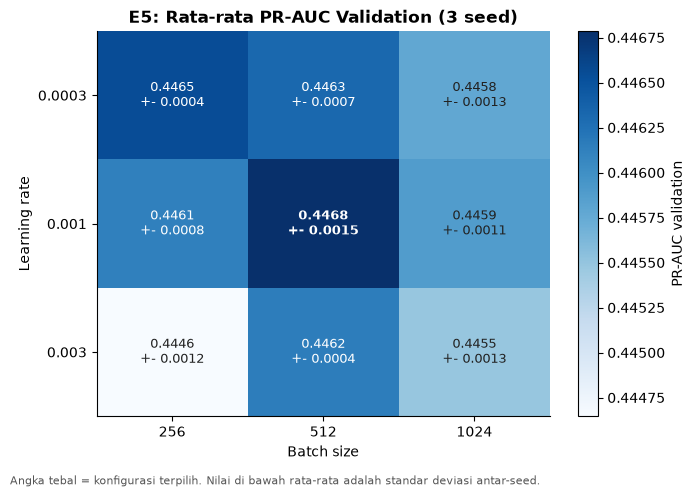

In [29]:
ringkas_e5["lr"] = [configs_e5[s]["learning_rate"] for s in ringkas_e5.index]
ringkas_e5["bs"] = [configs_e5[s]["batch_size"] for s in ringkas_e5.index]
pivot_mean = ringkas_e5.pivot(index="lr", columns="bs", values="val_pr_auc_mean")
pivot_std = ringkas_e5.pivot(index="lr", columns="bs", values="val_pr_auc_std")

fig, ax = plt.subplots(figsize=(7, 4.8))
im = ax.imshow(pivot_mean.values, cmap="Blues", aspect="auto")
ambang = pivot_mean.values.min() + 0.6 * (pivot_mean.values.max() - pivot_mean.values.min())
for i, lr in enumerate(pivot_mean.index):
    for j, bs in enumerate(pivot_mean.columns):
        m, s = pivot_mean.loc[lr, bs], pivot_std.loc[lr, bs]
        tebal = "bold" if nama_skenario(lr, bs) == pilih_e5 else "normal"
        ax.text(j, i, f"{m:.4f}\n+- {s:.4f}", ha="center", va="center", fontsize=9, fontweight=tebal,
                color="white" if m > ambang else "#222222")
ax.set_xticks(range(len(pivot_mean.columns)), [str(b) for b in pivot_mean.columns])
ax.set_yticks(range(len(pivot_mean.index)), [f"{l:g}" for l in pivot_mean.index])
ax.set_xlabel("Batch size")
ax.set_ylabel("Learning rate")
ax.grid(False)
ax.set_title("E5: Rata-rata PR-AUC Validation (3 seed)", fontweight="bold")
fig.colorbar(im, ax=ax, label="PR-AUC validation")
fig.text(0.01, -0.02, "Angka tebal = konfigurasi terpilih. Nilai di bawah rata-rata adalah standar deviasi antar-seed.",
         fontsize=8, color="#555555")
fig.tight_layout()
viz.save_fig(fig, "opt_01_heatmap_lr_batch")
plt.show()

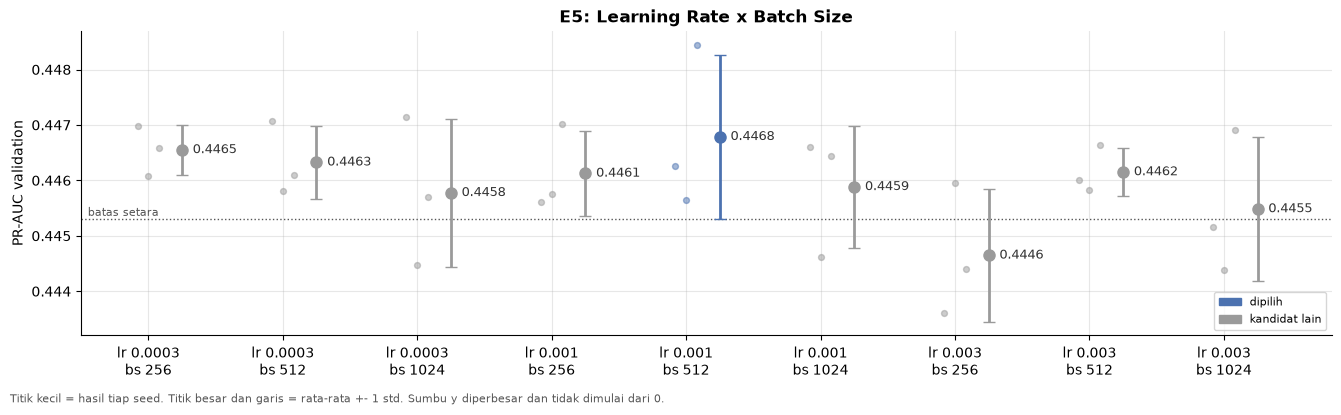

Rata-rata epoch terbaik:


bs,256,512,1024
lr,,,
0.0003,24.3,44.3,43.0
0.0010,15.3,18.3,17.7
0.0030,9.3,10.7,11.0


Rata-rata waktu per run (detik):


bs,256,512,1024
lr,,,
0.0003,115.0,120.0,90.0
0.0010,70.0,66.0,46.0
0.0030,56.0,45.0,38.0


In [30]:
urut = [nama_skenario(lr, bs) for lr in LR_LIST for bs in BS_LIST]
viz.plot_tahap(runs_e5, ringkas_e5.loc[urut], pilih_e5, "E5: Learning Rate x Batch Size",
               "opt_02_e5_dotplot", label_x={s: s.replace(", ", "\n") for s in urut})

print("Rata-rata epoch terbaik:")
display(ringkas_e5.pivot(index="lr", columns="bs", values="best_epoch_mean").round(1))
print("Rata-rata waktu per run (detik):")
display(ringkas_e5.pivot(index="lr", columns="bs", values="seconds_mean").round(0))

**Interpretasi:** Kesimpulan E5 mirip dengan notebook 03. Kesembilan kombinasi learning rate dan batch size menghasilkan PR-AUC validation yang hampir sama, yaitu di rentang 0,4446 sampai 0,4468, dengan selisih maksimum hanya 0,0022. Perlu diingat bahwa skala warna heatmap mencakup rentang yang sangat sempit, sehingga perbedaan warnanya terlihat mencolok padahal selisih angkanya kecil.

Beberapa pola yang terlihat:

- **Hanya satu kombinasi di luar batas setara**, yaitu learning rate 0,003 dengan batch size 256 (0,4446). Kombinasi ini paling berisik, karena langkah pembaruannya besar dan gradiennya dihitung dari batch kecil. Epoch terbaiknya juga paling awal (rata-rata 9,3), tanda model cepat melewati titik optimal.
- **Learning rate menentukan berapa lama model perlu dilatih.** Dengan learning rate 0,0003, epoch terbaik ada di 24 sampai 44. Dengan 0,001 di 15 sampai 18, dan dengan 0,003 di 9 sampai 11. Hasil akhirnya hampir sama, yang berbeda hanya kecepatan mencapainya.
- **Waktu training berbeda jauh.** Kombinasi tercepat (learning rate 0,003, batch 1024) butuh rata-rata 38 detik per run, sedangkan yang paling lama (learning rate 0,0003, batch 512) butuh 120 detik.

Sesuai aturan pemilihan, **learning rate 0,001 dengan batch size 512** terpilih karena rata-ratanya tertinggi (0,4468). Kombinasi ini kebetulan sama dengan nilai awal di notebook 03. Ada dua catatan yang perlu dicantumkan secara jujur. Pertama, kombinasi ini justru punya standar deviasi terbesar (0,0015). Kedua, ada alternatif yang setara dan lebih efisien, misalnya learning rate 0,003 dengan batch 512 (0,4462 +- 0,0004) yang sekitar 32% lebih cepat. Kami tetap mengikuti aturan yang sudah ditetapkan sebelum eksperimen, supaya pemilihan tidak berubah-ubah setelah melihat hasil.

## **6. Kurva Training Konfigurasi Terpilih (3 Seed)**

Kurva ini memperlihatkan perilaku konfigurasi terpilih di ketiga seed. Seperti di notebook 03, nilai train dihitung saat dropout aktif, sehingga garis train bisa berada di bawah validation.

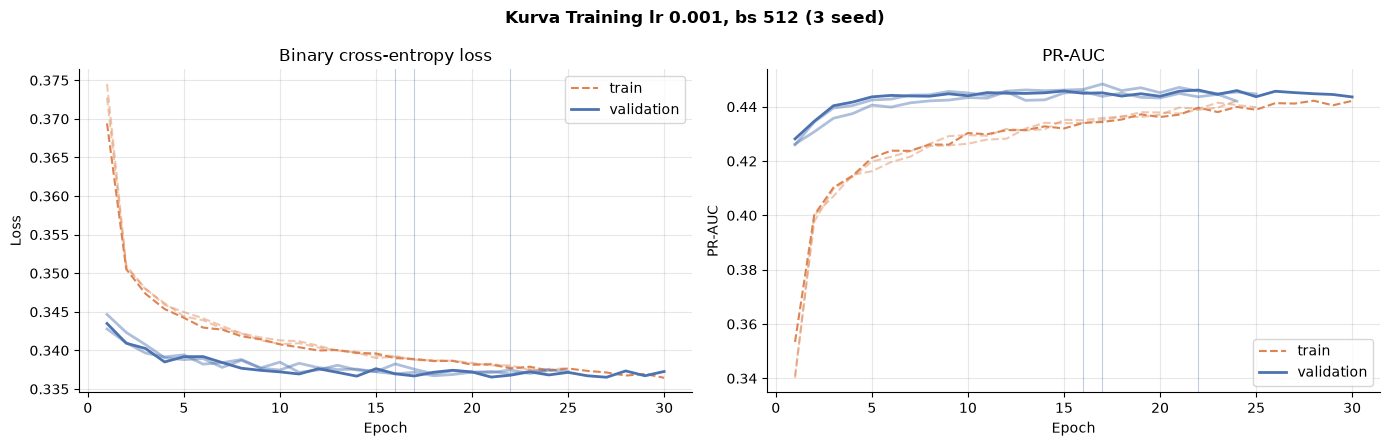

In [31]:
viz.plot_kurva({seed: hist_e5[f"{pilih_e5}|{seed}"] for seed in M.SEEDS},
               f"Kurva Training {pilih_e5} ({len(M.SEEDS)} seed)", "opt_03_kurva_e5_terpilih",
               loss_label="Binary cross-entropy loss")

**Interpretasi:** Konfigurasi terpilih sama persis dengan konfigurasi akhir notebook 03, jadi ketiga run ini adalah run yang dipakai ulang dan kurvanya identik dengan kurva di notebook 03. Epoch terbaik ada di epoch 22, 16, dan 17, lalu training berhenti 8 epoch setelahnya. Val loss mendatar sejak sekitar epoch 5, dan selisih PR-AUC train dan validation (dihitung tanpa dropout) rata-rata hanya 0,0030. Jadi tidak ada tanda overfitting.

## **7. Training Model Final Tanpa Fitur Unik**

Model final dilatih dengan konfigurasi terpilih memakai **seed 42**. Seed ini sudah ditetapkan sejak awal sebagai seed utama, jadi pemilihannya tidak didasarkan pada seed yang kebetulan memberi hasil terbaik. Dua callback dipakai:
- **EarlyStopping** memantau PR-AUC validation dengan patience 8 dan mengembalikan bobot terbaik.
- **ModelCheckpoint** menyimpan bobot dengan PR-AUC validation terbaik ke file selama training.

Setelah selesai, model disimpan ke `models/mlp_tanpa_fitur_unik.keras`. Hasilnya juga dibandingkan dengan run seed 42 di eksperimen E5 sebagai bukti bahwa training memang bisa diulang.

In [32]:
FINAL_HIST_PATH = config.RESULTS_DIR / "04_riwayat_model_final.json"

if RUN_EXPERIMENTS:
    model_final, ringkasan_final, hist_final = M.train_one(cfg_final, data, seed=42, run_name="final_tanpa_fitur_unik")
    model_final.save(FINAL_MODEL_PATH)
    M.save_json({"ringkasan": ringkasan_final, "history": hist_final}, FINAL_HIST_PATH)
else:
    model_final = keras.models.load_model(FINAL_MODEL_PATH)
    tersimpan = M.load_json(FINAL_HIST_PATH)
    ringkasan_final, hist_final = tersimpan["ringkasan"], tersimpan["history"]

e5_seed42 = runs_e5[(runs_e5["skenario"] == pilih_e5) & (runs_e5["seed"] == 42)].iloc[0]
print(f"Model tersimpan      : {FINAL_MODEL_PATH.relative_to(ROOT)} ({FINAL_MODEL_PATH.stat().st_size / 1024:.1f} KB)")
print(f"Epoch dijalankan     : {ringkasan_final['epochs_run']} (terbaik di epoch {ringkasan_final['best_epoch']})")
print(f"PR-AUC validation    : {ringkasan_final['val_pr_auc']:.6f}")
print(f"PR-AUC E5 seed 42    : {e5_seed42['val_pr_auc']:.6f}")
print("Hasil identik dengan E5:", np.isclose(ringkasan_final["val_pr_auc"], e5_seed42["val_pr_auc"], atol=1e-9))

Model tersimpan      : models\mlp_tanpa_fitur_unik.keras (167.7 KB)
Epoch dijalankan     : 30 (terbaik di epoch 22)
PR-AUC validation    : 0.446265
PR-AUC E5 seed 42    : 0.446265
Hasil identik dengan E5: True


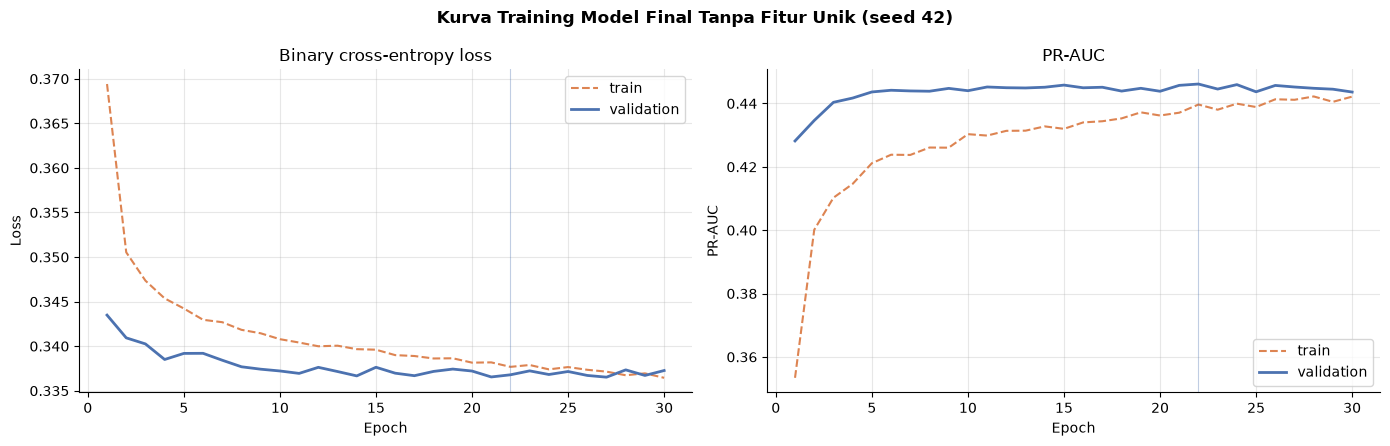

In [33]:
viz.plot_kurva({"seed 42": hist_final}, "Kurva Training Model Final Tanpa Fitur Unik (seed 42)",
               "opt_04_kurva_model_final", loss_label="Binary cross-entropy loss")

**Interpretasi:** Model final dengan seed 42 berjalan 30 epoch dengan bobot terbaik di epoch 22. PR-AUC validation-nya 0,446265, **sama persis** dengan run seed 42 di eksperimen E5. Ini membuktikan bahwa pengaturan seed dan operasi deterministik bekerja, sehingga model bisa dilatih ulang dengan hasil identik di environment yang sama.

File `mlp_tanpa_fitur_unik.keras` berukuran 167,7 KB. Ukurannya lebih besar dari bobot model saja (sekitar 43,5 KB) karena format `.keras` ikut menyimpan konfigurasi dan state optimizer Adam. Kurva trainingnya sama dengan kurva seed 42 di bagian sebelumnya.

## **8. Pemeriksaan Model Final di Data Validation (Threshold 0,5)**

Secara bawaan, probabilitas di atas 0,5 dianggap diabetes. Bagian ini melihat apa yang terjadi kalau aturan bawaan itu dipakai apa adanya. Hasilnya **belum** dipakai sebagai evaluasi akhir dan hanya dihitung di data validation. Tujuannya untuk melihat kelemahan model tanpa fitur unik, terutama kemampuan mendeteksi kelas diabetes.

In [34]:
prob_val = model_final.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()
y_val = data["y_val"].astype(int)
pred_05 = (prob_val >= 0.5).astype(int)

print(f"PR-AUC validation  : {average_precision_score(y_val, prob_val):.4f}")
print(f"ROC-AUC validation : {roc_auc_score(y_val, prob_val):.4f}")
print(f"Proporsi diprediksi diabetes (threshold 0,5): {pred_05.mean():.2%} (proporsi asli {y_val.mean():.2%})\n")
print(classification_report(y_val, pred_05, target_names=[config.CLASS_LABELS[0], config.CLASS_LABELS[1]], digits=4))

PR-AUC validation  : 0.4463
ROC-AUC validation : 0.8190
Proporsi diprediksi diabetes (threshold 0,5): 2.82% (proporsi asli 15.30%)

                precision    recall  f1-score   support

Tidak diabetes     0.8606    0.9873    0.9196     29080
      Diabetes     0.6192    0.1142    0.1929      5252

      accuracy                         0.8538     34332
     macro avg     0.7399    0.5508    0.5562     34332
  weighted avg     0.8236    0.8538    0.8084     34332



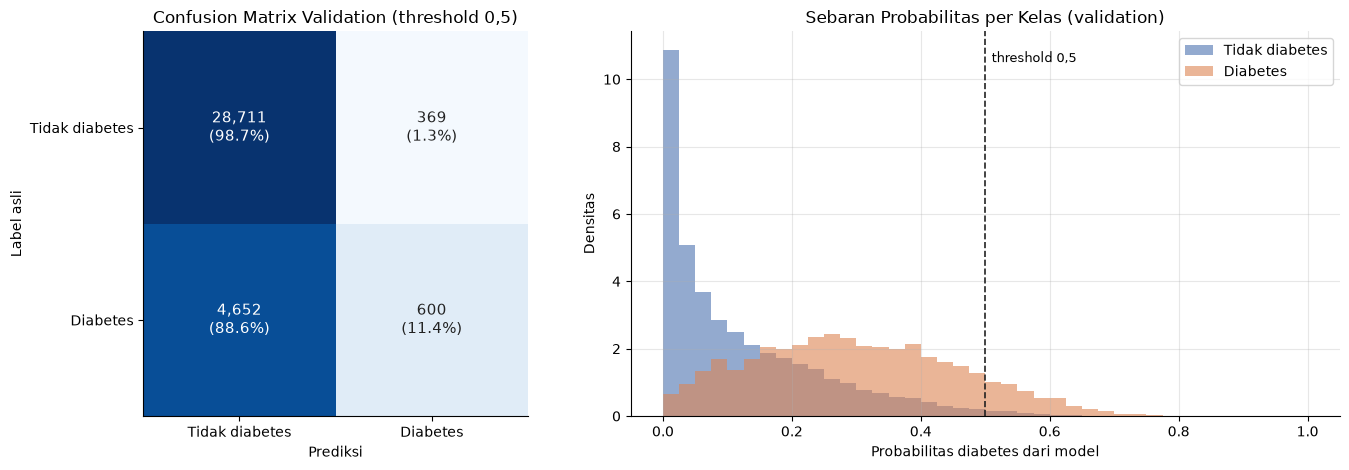

Median probabilitas kelas diabetes      : 0.291
Median probabilitas kelas tidak diabetes: 0.078
Kasus diabetes dengan probabilitas < 0,5: 88.58%


In [35]:
cm = confusion_matrix(y_val, pred_05)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})", ha="center", va="center", fontsize=11,
                color="white" if cm_pct[i, j] > 0.6 else "#222222")
labels = [config.CLASS_LABELS[0], config.CLASS_LABELS[1]]
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
ax.grid(False)
ax.set_title("Confusion Matrix Validation (threshold 0,5)")

ax = axes[1]
bins = np.linspace(0, 1, 41)
ax.hist(prob_val[y_val == 0], bins=bins, density=True, alpha=0.6, color="#4C72B0", label=config.CLASS_LABELS[0])
ax.hist(prob_val[y_val == 1], bins=bins, density=True, alpha=0.6, color="#DD8452", label=config.CLASS_LABELS[1])
ax.axvline(0.5, color="#222222", ls="--", lw=1.2)
ax.text(0.51, ax.get_ylim()[1] * 0.92, "threshold 0,5", fontsize=9)
ax.set_xlabel("Probabilitas diabetes dari model")
ax.set_ylabel("Densitas")
ax.set_title("Sebaran Probabilitas per Kelas (validation)")
ax.legend()
fig.tight_layout()
viz.save_fig(fig, "opt_05_validation_threshold_05")
plt.show()

print(f"Median probabilitas kelas diabetes      : {np.median(prob_val[y_val == 1]):.3f}")
print(f"Median probabilitas kelas tidak diabetes: {np.median(prob_val[y_val == 0]):.3f}")
print(f"Kasus diabetes dengan probabilitas < 0,5: {(prob_val[y_val == 1] < 0.5).mean():.2%}")

**Interpretasi:** Bagian ini memperlihatkan kelemahan terbesar model tanpa fitur unik.

Dari sisi kemampuan membedakan kelas, model sebenarnya cukup baik. ROC-AUC 0,8190, dan median probabilitas responden diabetes (0,291) hampir empat kali lipat median responden tidak diabetes (0,078). Masalahnya muncul ketika probabilitas diubah menjadi keputusan dengan threshold 0,5:

- Hanya **2,82%** responden yang diprediksi diabetes, padahal proporsi aslinya 15,30%.
- **Recall kelas diabetes hanya 11,42%.** Dari 5.252 responden diabetes, cuma 600 yang terdeteksi, dan 4.652 lainnya (88,6%) terlewat.
- Precision kelas diabetes 61,92%, tetapi F1-score-nya hanya 0,1929 karena recall yang sangat rendah.
- Accuracy 85,38% terlihat tinggi, tetapi hanya 0,7 poin di atas model yang selalu menebak "tidak diabetes" (84,70%).

Histogram menjelaskan penyebabnya. Probabilitas responden diabetes kebanyakan tersebar di 0,1 sampai 0,5 dan jarang melewati 0,5. Hal ini wajar, karena model yang dilatih dengan binary cross-entropy belajar mengikuti proporsi kelas di data. Dengan prevalensi diabetes sekitar 15%, model jarang cukup yakin untuk memberi probabilitas di atas 50%.

Jadi masalah utamanya bukan model yang gagal mengurutkan risiko, tetapi **threshold 0,5 yang tidak cocok untuk data tidak seimbang**. Untuk konteks skrining risiko diabetes, melewatkan 88,6% penderita jelas tidak bisa diterima. Inilah yang akan ditangani fitur unik pertama di notebook 05, yaitu Focal Loss dan penentuan threshold berdasarkan data validation.

## **9. Uji Model Tersimpan**

Model yang sudah disimpan dimuat ulang dari file, lalu prediksinya dibandingkan dengan model di memori. Setelah itu dilakukan simulasi alur aplikasi, yaitu input satu responden dalam bentuk dictionary, ditransformasi dengan scaler yang tersimpan, lalu diprediksi oleh model dari file.

In [36]:
model_file = keras.models.load_model(FINAL_MODEL_PATH)
prob_file = model_file.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()
print("Selisih maksimum prediksi (memori vs file):", float(np.max(np.abs(prob_file - prob_val))))

contoh = data["X_val_raw"].iloc[0]
input_form = {col: int(contoh[col]) for col in config.FEATURE_COLS}
X_app = prep.transform_features(pd.DataFrame([input_form]), prep.load_scaler())
prob_app = float(model_file.predict(X_app, verbose=0)[0, 0])
print("Input form :", input_form)
print(f"Probabilitas diabetes dari alur aplikasi: {prob_app:.4f}")
print(f"Probabilitas baris yang sama di validation: {prob_val[0]:.4f}")

Selisih maksimum prediksi (memori vs file): 0.0
Input form : {'HighBP': 0, 'HighChol': 0, 'CholCheck': 1, 'BMI': 27, 'Smoker': 1, 'Stroke': 0, 'HeartDiseaseorAttack': 0, 'PhysActivity': 0, 'Fruits': 1, 'Veggies': 1, 'HvyAlcoholConsump': 0, 'AnyHealthcare': 0, 'NoDocbcCost': 0, 'GenHlth': 2, 'MentHlth': 2, 'PhysHlth': 0, 'DiffWalk': 0, 'Sex': 1, 'Age': 6, 'Education': 4, 'Income': 5}
Probabilitas diabetes dari alur aplikasi: 0.0172
Probabilitas baris yang sama di validation: 0.0172


**Interpretasi:** Prediksi dari model yang dimuat ulang identik dengan model di memori (selisih maksimum 0,0), jadi file model tersimpan dengan benar. Simulasi alur aplikasi juga lolos. Input dictionary dengan nilai asli seperti `BMI: 27` ditransformasi dengan scaler dari file, lalu diprediksi oleh model dari file, dan hasilnya (0,0172) sama dengan probabilitas baris yang sama di data validation. Artinya rantai input form, scaler, lalu model sudah konsisten dengan proses training.

## **10. Menyimpan Konfigurasi Final**

Konfigurasi lengkap model tanpa fitur unik disimpan ke `reports/results/04_konfigurasi_final.json`. File ini dibaca notebook 05 (fitur unik 1), sehingga arsitektur, learning rate, dan batch size di notebook berikutnya dijamin sama.

In [37]:
konfig_final = {
    "konfigurasi": cfg_final,
    "label": M.config_label(cfg_final),
    "skenario_e5": pilih_e5,
    "seed_model_final": 42,
    "model_path": str(FINAL_MODEL_PATH.relative_to(ROOT)).replace("\\", "/"),
    "loss": "binary_crossentropy",
    "e5_val_pr_auc_mean": float(ringkas_e5.loc[pilih_e5, "val_pr_auc_mean"]),
    "e5_val_pr_auc_std": float(ringkas_e5.loc[pilih_e5, "val_pr_auc_std"]),
    "model_final_val_pr_auc": float(average_precision_score(y_val, prob_val)),
    "model_final_val_roc_auc": float(roc_auc_score(y_val, prob_val)),
    "model_final_best_epoch": int(ringkasan_final["best_epoch"]),
    "catatan": "Model tanpa fitur unik. Angka di file ini berasal dari data validation, bukan data test.",
}
M.save_json(konfig_final, config.RESULTS_DIR / "04_konfigurasi_final.json")
print(json.dumps(konfig_final, indent=2))

{
  "konfigurasi": {
    "hidden_units": [
      128,
      64
    ],
    "dropout": 0.2,
    "l2": 0.0,
    "batch_norm": false,
    "learning_rate": 0.001,
    "batch_size": 512
  },
  "label": "[128-64] do=0.2",
  "skenario_e5": "lr 0.001, bs 512",
  "seed_model_final": 42,
  "model_path": "models/mlp_tanpa_fitur_unik.keras",
  "loss": "binary_crossentropy",
  "e5_val_pr_auc_mean": 0.4467859238306255,
  "e5_val_pr_auc_std": 0.0014749422578506975,
  "model_final_val_pr_auc": 0.44626464194121984,
  "model_final_val_roc_auc": 0.8190144535231746,
  "model_final_best_epoch": 22,
  "catatan": "Model tanpa fitur unik. Angka di file ini berasal dari data validation, bukan data test."
}


## **11. Kesimpulan dan Langkah Berikutnya**

Model tanpa fitur unik yang dihasilkan notebook ini:

| Komponen | Nilai |
|---|---|
| Arsitektur | MLP [128-64], ReLU, He normal, dropout 0,2 |
| Optimizer | Adam, learning rate 0,001 |
| Batch size | 512 |
| Loss | Binary cross-entropy |
| Callback | EarlyStopping (patience 8) dan ModelCheckpoint, memantau PR-AUC validation |
| Seed model final | 42 (epoch terbaik 22) |
| PR-AUC validation | 0,4463 (rata-rata 3 seed 0,4468 +- 0,0015) |
| ROC-AUC validation | 0,8190 |
| Recall diabetes pada threshold 0,5 | 11,42% |
| File | `models/mlp_tanpa_fitur_unik.keras` |

Temuan utamanya:
1. Dalam rentang yang diuji, learning rate dan batch size hampir tidak memengaruhi PR-AUC (selisih maksimum 0,0022). Keduanya lebih berpengaruh pada lama training.
2. Training terbukti bisa diulang dengan hasil identik.
3. Model sudah cukup baik mengurutkan risiko (ROC-AUC 0,819), tetapi dengan threshold 0,5 model hanya menemukan 11,42% penderita diabetes. Ini kelemahan yang paling penting untuk diperbaiki.

Semua angka di atas berasal dari data validation dan **bukan hasil evaluasi akhir**.

**Langkah berikutnya:** notebook `05_fitur_unik_imbalance.ipynb` membaca `reports/results/04_konfigurasi_final.json`, memakai arsitektur dan hyperparameter yang sama, mengganti loss menjadi Focal Loss, lalu menentukan threshold di data validation. Hasilnya dibandingkan dengan model di notebook ini untuk membuktikan dampak fitur unik pertama.